# 06 · Which market should a home battery trade?

Everything so far traded the battery against the **imbalance price**, set after each half-hour
by whether the whole system ended up short or long. Real operators mostly lock in prices in
advance. In GB the main venue is the **day-ahead auction** (N2EX): bids close at 09:50 on D-1,
hourly prices are published by 10:00. Our 09:00 decision time fits that deadline exactly.

This notebook compares the two markets on the same test year, same battery (the day-ahead version
holds one power level per hour, because the auction trades whole hours), same model framework:

1. How do the two prices behave?
2. How much value does each offer with perfect foresight?
3. How much does the model capture in each, and why the difference?

Inputs: the logged experiments `calibrated` (imbalance, production strategy) and `day_ahead`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import style

from flexcast.backtest import summarise
from flexcast.history import History
from flexcast.settlement import LONDON
from flexcast.storage import Storage

style.use()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
store = Storage(f"file://{ROOT / 'data'}")
history = History.load(store)
RUNS = {"imbalance": "calibrated", "day ahead": "day_ahead"}
daily = {m: store.read_parquet(f"backtest/experiments/{e}/daily.parquet") for m, e in RUNS.items()}
fc = {m: store.read_parquet(f"backtest/experiments/{e}/forecasts.parquet") for m, e in RUNS.items()}
MODEL = {"imbalance": "lgbm_risk_aware", "day ahead": "lgbm_risk_aware"}  # production rows
NAIVE = {"imbalance": "naive_last_day", "day ahead": "naive_day_ahead"}

## 1. Two prices for the same half-hours

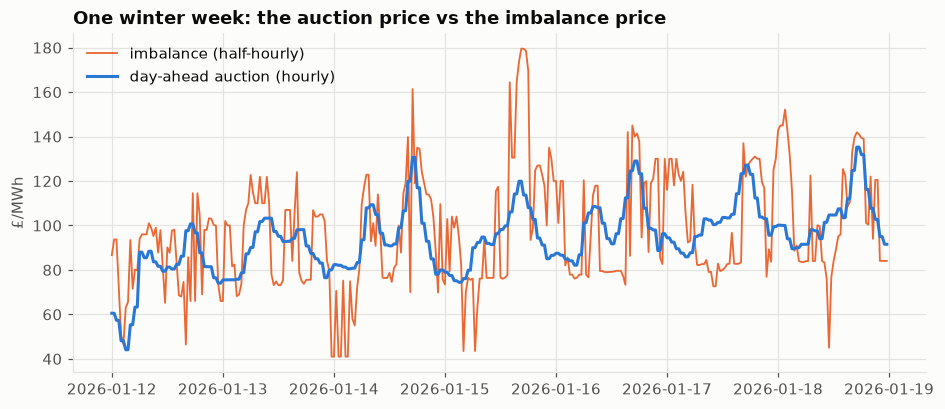

,imbalance,day ahead
std £/MWh,67.69,40.72
typical hour-to-hour move £,13.59,5.23
corr with same time 1 day earlier,0.22,0.64
median daily spread £,123.05,62.16


In [2]:
imb = history.prices.set_index("start_time")["price"]
da = history.day_ahead.set_index("start_time")["price"]
both = pd.DataFrame({"imbalance": imb, "day ahead": da}).dropna()
week = both.loc["2026-01-12":"2026-01-18"]
t = week.index.tz_convert(LONDON)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, week["imbalance"], color=style.ORANGE, linewidth=1.2, label="imbalance (half-hourly)")
ax.plot(t, week["day ahead"], color=style.BLUE, label="day-ahead auction (hourly)")
ax.set(title="One winter week: the auction price vs the imbalance price", ylabel="£/MWh")
ax.legend(loc="upper left")
plt.show()


def describe(s: pd.Series) -> dict[str, float]:
    regular = s.asfreq("30min")
    hourly = s.resample("1h").mean()  # compare both markets hour to hour
    day = s.groupby(s.index.tz_convert(LONDON).date)
    return {
        "std £/MWh": s.std(),
        "typical hour-to-hour move £": hourly.diff().abs().median(),
        "corr with same time 1 day earlier": regular.autocorr(48),
        "median daily spread £": (day.max() - day.min()).median(),
    }


pd.DataFrame({m: describe(both[m]) for m in both}).style.format("{:.2f}")

The auction price has about **half the daily spread** of the imbalance price (median ~£62 vs
~£123), so there is less value on offer. But it moves far less hour to hour and repeats much more
strongly from one day to the next (correlation with the same time yesterday ~0.64 vs ~0.22). The
imbalance price's extra spread is largely noise that can't be known a day ahead.

## 2–3. Value available and value captured

In [3]:
rows = []
for m in RUNS:
    s = summarise(daily[m])
    rows.append(
        {
            "market": m,
            "perfect foresight £/yr": s.loc["perfect", "gbp_per_year"],
            "model £/yr": s.loc[MODEL[m], "gbp_per_year"],
            "naive £/yr": s.loc[NAIVE[m], "gbp_per_year"],
            "model % of perfect": s.loc[MODEL[m], "pct_of_perfect"],
            "naive % of perfect": s.loc[NAIVE[m], "pct_of_perfect"],
            "MAE £/MWh": s.loc[MODEL[m], "mae"],
            "p10–p90 coverage": s.loc[MODEL[m], "coverage_80"],
        }
    )
markets = pd.DataFrame(rows).set_index("market")
markets.style.format(
    {c: "{:.1f}" for c in markets.columns if "coverage" not in c} | {"p10–p90 coverage": "{:.0%}"}
)

,perfect foresight £/yr,model £/yr,naive £/yr,model % of perfect,naive % of perfect,MAE £/MWh,p10–p90 coverage
market,,,,,,,
imbalance,270.7,36.6,-148.7,13.5,-54.9,30.5,77%
day ahead,69.6,45.5,15.5,65.4,22.2,12.4,78%


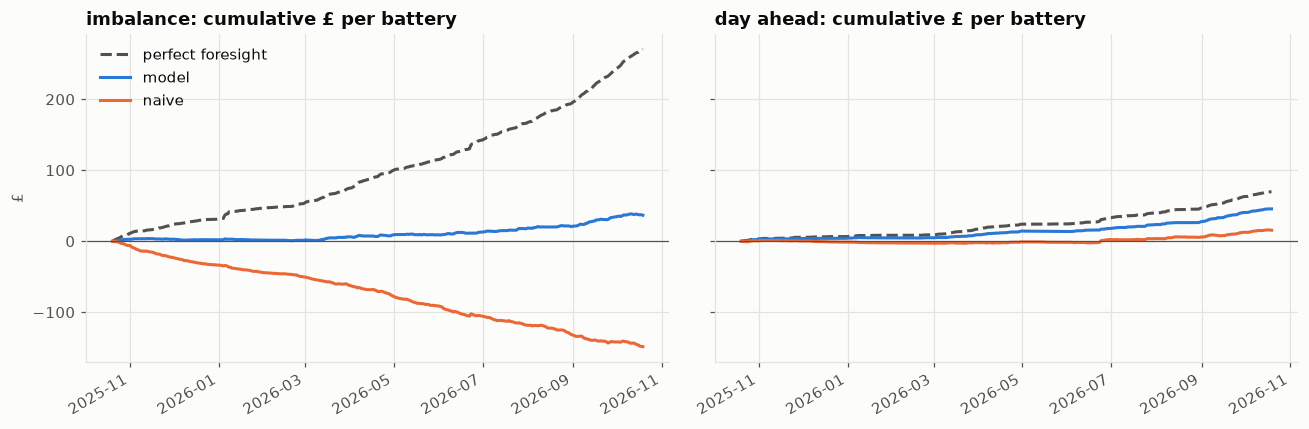

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, m in zip(axes, RUNS, strict=True):
    wide = daily[m].pivot(index="target_date", columns="strategy", values="value_gbp").sort_index()
    for col, color, label in (
        ("perfect", style.TEXT_2, "perfect foresight"),
        (MODEL[m], style.BLUE, "model"),
        (NAIVE[m], style.ORANGE, "naive"),
    ):
        ax.plot(
            wide.index,
            wide[col].cumsum(),
            color=color,
            label=label,
            linestyle="--" if col == "perfect" else "-",
        )
    ax.set(title=f"{m}: cumulative £ per battery")
    ax.axhline(0, color=style.TEXT_2, linewidth=0.8)
axes[0].set(ylabel="£")
axes[0].legend(loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Why the gap: does the forecast get each day's *shape* right?

The battery only needs to know which hours are cheap and which are dear. Rank correlation
between forecast and actual within each day measures exactly that.

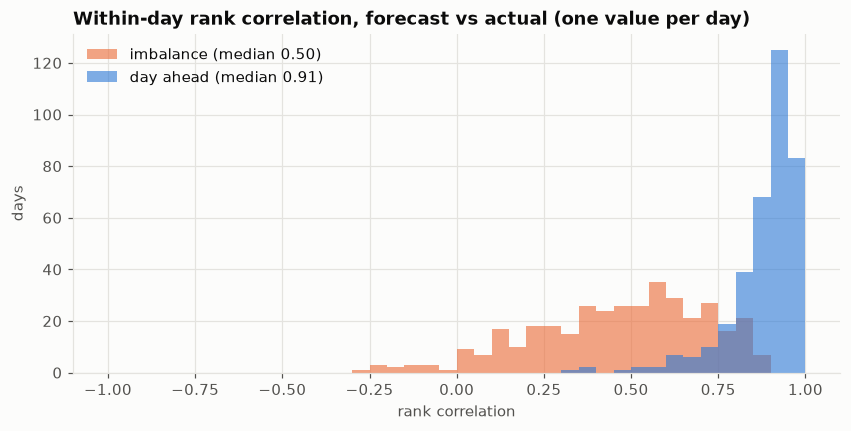

In [5]:
def daily_shape(f: pd.DataFrame, strategy: str) -> pd.Series:
    g = f[f.strategy == strategy]
    return g.groupby("target_date").apply(lambda d: d.p50.rank().corr(d.actual.rank()))


shape = pd.DataFrame({m: daily_shape(fc[m], MODEL[m]) for m in RUNS})
fig, ax = plt.subplots()
bins = np.linspace(-1, 1, 41)
for m, color in zip(RUNS, (style.ORANGE, style.BLUE), strict=True):
    ax.hist(
        shape[m].dropna(),
        bins=bins,
        color=color,
        alpha=0.6,
        label=f"{m} (median {shape[m].median():.2f})",
    )
ax.set(
    title="Within-day rank correlation, forecast vs actual (one value per day)",
    xlabel="rank correlation",
    ylabel="days",
)
ax.legend(loc="upper left")
plt.show()

## Takeaways

- **Less value on offer, but far more of it capturable.** Perfect foresight is worth ~£70/yr in
  the auction vs ~£271 against the imbalance price, but the model captures ~65% of the auction's
  value vs ~13.5% of the imbalance price's, and so earns *more* (~£46 vs ~£37 per battery-year).
- **The reason is the shape.** Within each day the model ranks the auction's cheap and dear hours
  almost perfectly (median rank correlation ~0.91 vs ~0.50). The battery only needs the ranking.
- **Even naive works here.** Copying yesterday's auction prices earns money (~£15/yr), because
  yesterday's prices are known at decision time and repeat strongly; the naive imbalance strategy
  lost ~£149.
- **This is why operators trade in advance.** The imbalance price's large theoretical value sits
  in spikes nobody can see a day ahead. Locking in the auction price first, then re-trading the
  imbalance price closer to real time, is how that remaining value would be pursued: a natural
  next step, not built here.
- **The model work in checkpoints A–C carried over:** same features, tuning and calibration, plus
  yesterday's auction prices.